# 01 – How do big tech IPOs trade in their first year?

Before modelling Anthropic, we need a **base rate**: what usually happens to a big, hyped tech IPO?

We take 21 comparables (`data/comparables.csv`), download daily closes from Yahoo Finance, and express every
price as **% of the IPO offer price** (offer = 100). That puts Google 2004 and SpaceX 2026 on the same scale.

⚠️ Offer prices are hand-entered. Check them against each company's final prospectus (424B4 on SEC EDGAR).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import pandas as pd, matplotlib.pyplot as plt
import ipo

comps = ipo.load_comparables("../data/comparables.csv")
paths = ipo.build_paths(comps)
paths.to_csv("../data/paths.csv", index_label="trading_day")
comps

,ticker,name,ipo_date,offer_price,sector
0,GOOGL,Google,2004-08-19,85,internet
1,V,Visa,2008-03-19,44,fintech
2,GM,General Motors,2010-11-18,33,auto
3,META,Facebook,2012-05-18,38,internet
4,BABA,Alibaba,2014-09-19,68,internet
5,SNAP,Snap,2017-03-02,17,internet
6,LYFT,Lyft,2019-03-29,72,internet
7,PINS,Pinterest,2019-04-18,19,internet
8,ZM,Zoom,2019-04-18,36,software
9,UBER,Uber,2019-05-10,45,internet


## Return vs the offer price at each horizon
`day 1` is the first-day "pop". `peak day` counts trading days after listing.

In [2]:
summary = ipo.summary(paths)
summary

,day 1,1 month,3 months,6 months,1 year,peak,peak day
GOOGL,18.0,40.4,102.9,132.8,229.4,269.3,232
V,28.4,56.8,90.6,45.7,19.7,101.1,34
GM,3.6,2.3,10.6,-5.5,-34.0,18.1,34
META,0.6,-16.0,-49.9,-39.7,-33.8,0.6,0
BABA,38.1,29.8,60.7,23.9,-6.0,75.2,36
SNAP,44.0,32.5,25.5,-12.0,5.9,59.4,1
LYFT,8.7,-16.9,-8.7,-42.6,-62.6,8.7,0
PINS,28.4,36.1,34.5,36.8,-8.3,92.4,86
ZM,72.2,135.2,159.4,86.2,313.9,343.2,233
UBER,-7.6,-5.7,-11.0,-39.2,-29.7,3.1,34


In [3]:
summary.median(numeric_only=True)

day 1        29.10
1 month      36.10
3 months     54.00
6 months     42.80
1 year       40.65
peak        141.10
peak day     36.00
dtype: float64

## The catch: almost nobody buys at the offer price

The pop goes to institutions that get allocations at the offer price. If you buy at the **close of day 1**, your
starting point is already up by the pop. Rebase each path to the first close and compare.

In [4]:
from_close = ipo.rebase_to_first_close(paths) - 100
from_offer = paths - 100
rows = []
for h, d in ipo.HORIZONS.items():
    if d == 0: continue
    a, b = from_offer.iloc[d].dropna(), from_close.iloc[d].dropna()
    rows.append({"horizon": h, "median if bought at offer": a.median(), "% losing (offer)": (a < 0).mean() * 100,
                 "median if bought at day-1 close": b.median(), "% losing (day-1 close)": (b < 0).mean() * 100})
pd.DataFrame(rows).round(1)

,horizon,median if bought at offer,% losing (offer),median if bought at day-1 close,% losing (day-1 close)
0,1 month,36.1,19.0,-1.3,52.4
1,3 months,54.0,19.0,6.8,38.1
2,6 months,42.8,35.0,-9.5,55.0
3,1 year,40.7,40.0,-9.9,60.0


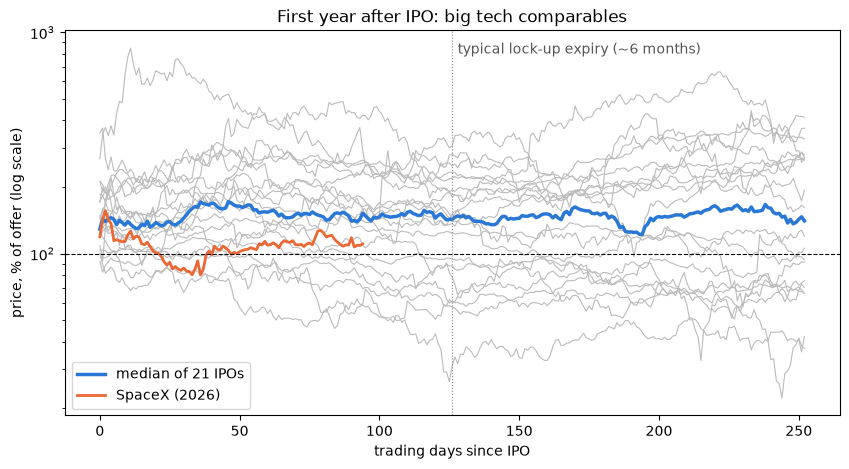

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
for t in paths:
    ax.plot(paths[t], color="#bbb", lw=0.8)
ax.plot(paths.median(axis=1), color="#2a78d6", lw=2.5, label="median of 21 IPOs")
ax.plot(paths["SPCX"], color="#eb6834", lw=2, label="SpaceX (2026)")
ax.axhline(100, color="k", lw=0.8, ls="--")
ax.axvline(126, color="#888", lw=0.8, ls=":")
ax.text(128, ax.get_ylim()[1] * 0.9, "typical lock-up expiry (~6 months)", color="#555")
ax.set(yscale="log", xlabel="trading days since IPO", ylabel="price, % of offer (log scale)",
       title="First year after IPO: big tech comparables")
ax.legend(); plt.show()

## Takeaways so far
1. Getting an allocation **at the offer price** has paid off. The median comparable is up roughly 40% after a year.
2. Buying **at the first-day close** is roughly a coin flip, and slightly worse: the median is about −10% after a year, and about 60% of these lost money.
3. **Caveat (selection bias):** this list is famous IPOs we remembered, which skews towards winners. A fairer next step is to use *every* US IPO over $1B (Jay Ritter's dataset).

## Next steps
- Add features for each IPO: whether the price range was revised, price-to-sales at the offer, and the Nasdaq's return in the prior month.
- Regress the day-1 return and the 6-month return on those features.
- Plug in Anthropic's numbers when its price range is published (expected around mid-November 2026).